# Experiment 8: Logistic Regression for Classification

## Import libraries

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix,
                             classification_report, roc_curve, roc_auc_score, precision_recall_curve,
                             average_precision_score, log_loss, ConfusionMatrixDisplay)

sns.set_theme(style="whitegrid")
np.random.seed(42)
RS = 42

## Load data

Shape: (569, 30)
Classes: {0: np.str_('malignant'), 1: np.str_('benign')}


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


target
benign       357
malignant    212
Name: count, dtype: int64


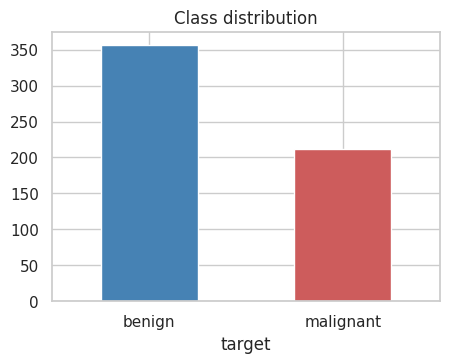

Missing values: 0


,mean,std,min,max
mean radius,14.127,3.524,6.981,28.110
mean texture,19.290,4.301,9.710,39.280
mean perimeter,91.969,24.299,43.790,188.500
mean area,654.889,351.914,143.500,2501.000
mean smoothness,0.096,0.014,0.053,0.163
mean compactness,0.104,0.053,0.019,0.345
mean concavity,0.089,0.080,0.000,0.427
mean concave points,0.049,0.039,0.000,0.201
mean symmetry,0.181,0.027,0.106,0.304
mean fractal dimension,0.063,0.007,0.050,0.097


In [2]:
data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target
print("Shape:", X.shape)
print("Classes:", dict(enumerate(data.target_names)))
display(X.head())

counts = y.map(dict(enumerate(data.target_names))).value_counts()
print(counts)
counts.plot(kind="bar", rot=0, color=["steelblue", "indianred"], figsize=(5, 3.5), title="Class distribution")
plt.show()

print("Missing values:", X.isnull().sum().sum())
X.describe().T[["mean", "std", "min", "max"]].head(10).round(3)

## Train-test split and scaling

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=RS, stratify=y)
scaler = StandardScaler().fit(X_train)
Xtr = pd.DataFrame(scaler.transform(X_train), columns=X.columns, index=X_train.index)
Xte = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)
print("Train:", Xtr.shape, "| Test:", Xte.shape)

Train: (426, 30) | Test: (143, 30)


## Fit logistic regression

In [4]:
clf = LogisticRegression(max_iter=5000, random_state=RS)
clf.fit(Xtr, y_train)
print("Intercept:", clf.intercept_.round(4))
print("Iterations:", clf.n_iter_)

Intercept: [0.2806]
Iterations: [19]


## Model parameters and odds ratios

,feature,coefficient,odds_ratio
0,worst texture,-1.2501,0.2865
1,radius error,-1.0701,0.3430
2,worst symmetry,-0.9570,0.3840
3,worst concave points,-0.9419,0.3899
4,area error,-0.9411,0.3902
5,worst area,-0.9258,0.3962
6,worst radius,-0.9175,0.3995
7,worst concavity,-0.7968,0.4508
8,worst perimeter,-0.7212,0.4862
9,mean concave points,-0.6769,0.5082


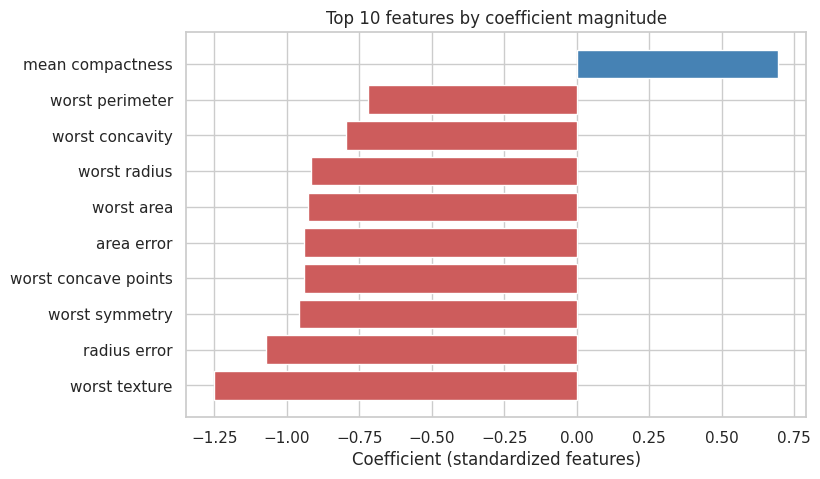

In [5]:
params = pd.DataFrame({"feature": X.columns, "coefficient": clf.coef_[0]})
params["odds_ratio"] = np.exp(params["coefficient"])
params = params.sort_values("coefficient")
display(params.round(4).reset_index(drop=True))

top = params.reindex(params["coefficient"].abs().sort_values(ascending=False).index).head(10).sort_values("coefficient")
plt.figure(figsize=(8, 5))
plt.barh(top["feature"], top["coefficient"], color=np.where(top["coefficient"] > 0, "steelblue", "indianred"))
plt.xlabel("Coefficient (standardized features)")
plt.title("Top 10 features by coefficient magnitude")
plt.show()

## Predictions and probabilities

,actual,predicted,P(benign)
0,1,1,0.9690
1,0,0,0.0004
2,1,1,0.5594
3,1,1,0.9389
4,0,0,0.1755
5,0,0,0.0000
6,0,0,0.0028
7,0,0,0.0008
8,0,0,0.0007
9,1,1,0.9999


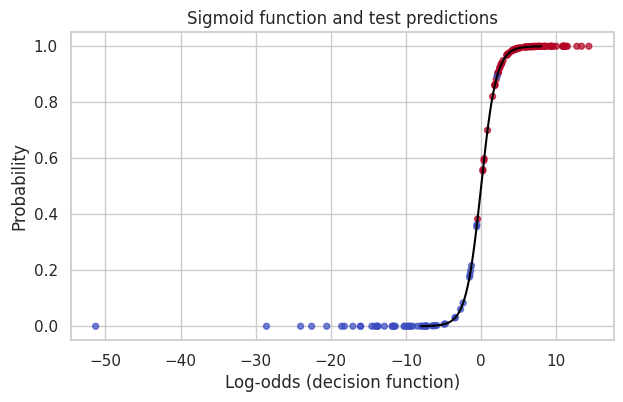

In [6]:
y_pred = clf.predict(Xte)
y_prob = clf.predict_proba(Xte)[:, 1]
display(pd.DataFrame({"actual": y_test.values[:10], "predicted": y_pred[:10], "P(benign)": y_prob[:10].round(4)}))

z = clf.decision_function(Xte)
plt.figure(figsize=(7, 4))
xs = np.linspace(-8, 8, 300)
plt.plot(xs, 1 / (1 + np.exp(-xs)), color="black", label="sigmoid")
plt.scatter(z, y_prob, c=y_test, cmap="coolwarm", s=18, alpha=0.7)
plt.xlabel("Log-odds (decision function)"); plt.ylabel("Probability"); plt.title("Sigmoid function and test predictions")
plt.show()

## Evaluation metrics

Accuracy : 0.986
Precision: 0.9889
Recall   : 0.9889
F1-score : 0.9889
ROC AUC  : 0.9977
Log loss : 0.0679
Train accuracy: 0.9883
[[52  1]
 [ 1 89]]


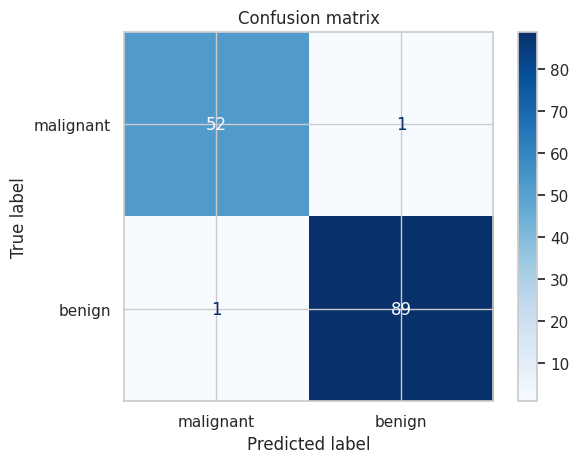

              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        53
      benign       0.99      0.99      0.99        90

    accuracy                           0.99       143
   macro avg       0.99      0.99      0.99       143
weighted avg       0.99      0.99      0.99       143



In [7]:
print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall   :", round(recall_score(y_test, y_pred), 4))
print("F1-score :", round(f1_score(y_test, y_pred), 4))
print("ROC AUC  :", round(roc_auc_score(y_test, y_prob), 4))
print("Log loss :", round(log_loss(y_test, y_prob), 4))
print("Train accuracy:", round(clf.score(Xtr, y_train), 4))

cm = confusion_matrix(y_test, y_pred)
print(cm)
ConfusionMatrixDisplay(cm, display_labels=data.target_names).plot(cmap="Blues")
plt.title("Confusion matrix")
plt.show()

print(classification_report(y_test, y_pred, target_names=data.target_names))

## ROC and precision-recall curves

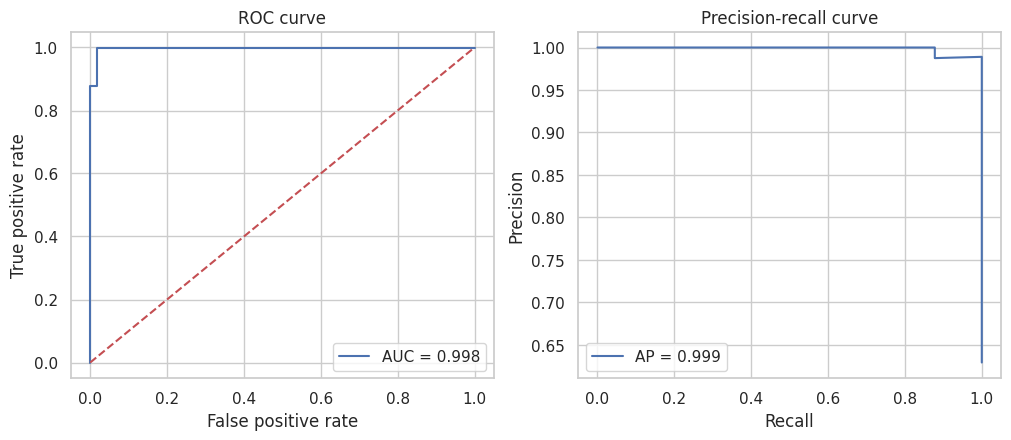

In [8]:
fpr, tpr, _ = roc_curve(y_test, y_prob)
prec, rec, _ = precision_recall_curve(y_test, y_prob)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, y_prob):.3f}")
axes[0].plot([0, 1], [0, 1], "r--")
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate"); axes[0].set_title("ROC curve"); axes[0].legend()
axes[1].plot(rec, prec, label=f"AP = {average_precision_score(y_test, y_prob):.3f}")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].set_title("Precision-recall curve"); axes[1].legend()
plt.show()

## Decision threshold analysis

In [9]:
rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    pred_t = (y_prob >= t).astype(int)
    rows.append([t, accuracy_score(y_test, pred_t), precision_score(y_test, pred_t), recall_score(y_test, pred_t), f1_score(y_test, pred_t)])
pd.DataFrame(rows, columns=["threshold", "accuracy", "precision", "recall", "f1"]).round(4)

,threshold,accuracy,precision,recall,f1
0,0.3,0.9790,0.9677,1.0000,0.9836
1,0.4,0.9860,0.9889,0.9889,0.9889
2,0.5,0.9860,0.9889,0.9889,0.9889
3,0.6,0.9580,0.9884,0.9444,0.9659
4,0.7,0.9510,0.9882,0.9333,0.9600
5,0.8,0.9510,0.9882,0.9333,0.9600
6,0.9,0.9231,1.0000,0.8778,0.9349


## Cross-validation

In [10]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)
from sklearn.pipeline import make_pipeline
pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))
for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    s = cross_val_score(pipe, X, y, cv=skf, scoring=metric)
    print(f"{metric:10s}: {s.round(4)} | mean = {s.mean():.4f}")

accuracy  : [0.9737 0.9474 0.9649 0.9912 0.9912] | mean = 0.9737
precision : [0.9857 0.9221 0.9474 1.     0.9861] | mean = 0.9683
recall    : [0.9718 1.     1.     0.9861 1.    ] | mean = 0.9916
f1        : [0.9787 0.9595 0.973  0.993  0.993 ] | mean = 0.9794
roc_auc   : [0.9951 0.9977 0.9851 1.     0.9987] | mean = 0.9953


## Effect of regularization strength

,C,train_acc,test_acc,sum_abs_coef
0,0.001,0.8920,0.9161,1.3895
1,0.010,0.9577,0.9371,3.9488
2,0.100,0.9836,0.9790,8.5990
3,1.000,0.9883,0.9860,16.7895
4,10.000,0.9906,0.9720,35.2298
5,100.000,0.9977,0.9441,114.1470


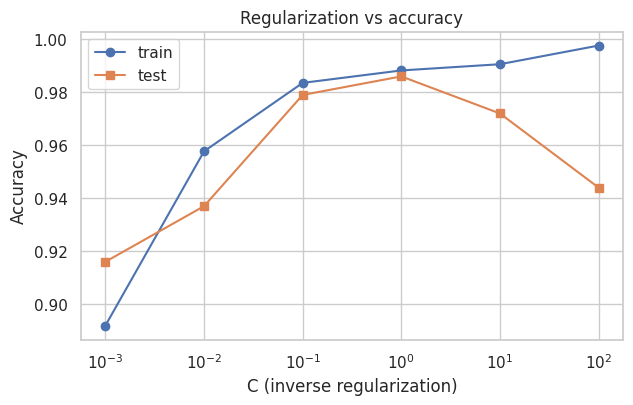

In [11]:
rows = []
for C_val in [0.001, 0.01, 0.1, 1, 10, 100]:
    m = LogisticRegression(C=C_val, max_iter=5000, random_state=RS).fit(Xtr, y_train)
    rows.append([C_val, m.score(Xtr, y_train), m.score(Xte, y_test), np.abs(m.coef_).sum()])
reg = pd.DataFrame(rows, columns=["C", "train_acc", "test_acc", "sum_abs_coef"])
display(reg.round(4))

plt.figure(figsize=(7, 4))
plt.semilogx(reg["C"], reg["train_acc"], marker="o", label="train")
plt.semilogx(reg["C"], reg["test_acc"], marker="s", label="test")
plt.xlabel("C (inverse regularization)"); plt.ylabel("Accuracy"); plt.legend(); plt.title("Regularization vs accuracy")
plt.show()

## Statistical inference on parameters (statsmodels Logit)

In [12]:
cols = ["mean texture", "mean smoothness", "mean concavity", "mean symmetry", "mean fractal dimension"]
Xs = sm.add_constant(Xtr[cols])
logit = sm.Logit(y_train, Xs).fit(disp=False)
print(logit.summary())

ci = logit.conf_int()
ci.columns = ["2.5%", "97.5%"]
inference = pd.concat([logit.params.rename("coef"), np.exp(logit.params).rename("odds_ratio"), np.exp(ci), logit.pvalues.rename("p_value")], axis=1)
display(inference.round(4))

Xs_test = sm.add_constant(Xte[cols])
pred_sm = (logit.predict(Xs_test) >= 0.5).astype(int)
print("statsmodels model test accuracy:", round(accuracy_score(y_test, pred_sm), 4))
print("McFadden pseudo R-squared:", round(logit.prsquared, 4))

                           Logit Regression Results                           
Dep. Variable:                 target   No. Observations:                  426
Model:                          Logit   Df Residuals:                      420
Method:                           MLE   Df Model:                            5
Date:                Tue, 20 Oct 2026   Pseudo R-squ.:                  0.7090
Time:                        18:35:13   Log-Likelihood:                -81.910
converged:                       True   LL-Null:                       -281.44
Covariance Type:            nonrobust   LLR p-value:                 4.729e-84
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                      0.9603      0.223      4.303      0.000       0.523       1.398
mean texture              -1.4205      0.248     -5.728      0.000      -1.907      -0.934
mean

,coef,odds_ratio,2.5%,97.5%,p_value
const,0.9603,2.6126,1.6869,4.0463,0.0000
mean texture,-1.4205,0.2416,0.1486,0.3928,0.0000
mean smoothness,-1.8178,0.1624,0.0816,0.3232,0.0000
mean concavity,-3.5506,0.0287,0.0118,0.0696,0.0000
mean symmetry,-0.7328,0.4805,0.2658,0.8688,0.0153
mean fractal dimension,2.8903,17.9987,7.8901,41.0584,0.0000


statsmodels model test accuracy: 0.9301
McFadden pseudo R-squared: 0.709
